In [7]:
import pyranges as pr
import gzip
import pandas as pd
import numpy as np
from scipy.sparse import dok_matrix

from hicexplorer import hicConvertFormat

In [8]:
path_interactions = "/home/joachim/data/MHH/epigenetic_graph_analyzer/phic/GSM6505208_Md_CapHiC_Merged_All-Tr_2ndBioRep_Chicago_output_washU_text.txt.gz"
path_output_2d = "/home/joachim/data/MHH/epigenetic_graph_analyzer/phic/GSM6505208_Md_CapHiC_Merged_All-Tr_2ndBioRep_Chicago_output_washU_text.csv"
path_output_cool = "/home/joachim/data/MHH/epigenetic_graph_analyzer/phic/GSM6505208_Md_CapHiC_Merged_All-Tr_2ndBioRep_Chicago_output_washU_text.cool"
path_mm10_chromosome_size = "/home/joachim/data/MHH/epigenetic_graph_analyzer/mm10.chrom.sizes"
path_promoter = "/home/joachim/data/MHH/epigenetic_graph_analyzer/mm10_promoter.bed"


In [9]:
pd_interactions = pd.read_table(path_interactions, header=None, sep='\t|,', compression='gzip')

In [10]:
pd_interactions

,0,1,2,3,4,5,6
0,chr1,3100832,3102475,chr1,88220832,88222715,20.75
1,chr1,3100832,3102475,chr1,88239615,88243256,7.79
2,chr1,3100832,3102475,chr1,88265935,88274374,7.79
3,chr1,3100832,3102475,chr1,88278578,88280173,14.24
4,chr1,3100832,3102475,chr10,53085931,53086971,5.24
...,...,...,...,...,...,...,...
324460,chrY,1304307,1309275,chr9,8775476,8777570,7.28
324461,chrY,1304307,1309275,chrY,790667,792380,5.28
324462,chrY,1304307,1309275,chrY,981956,982979,7.06
324463,chrY,1304307,1309275,chrY,1017923,1018908,5.10


In [11]:
pd_interactions.to_csv(path_output_2d, index=False, header=False, sep='\t')

In [74]:
args = "--matrices {} --outFileName {} --inputFormat 2D-text --outputFormat cool -r 1000 --chromosomeSizes {}".format(path_output_2d, path_output_cool, path_mm10_chromosome_size).split()
hicConvertFormat.main(args)

ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/home/joachim/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 262, in getRegionBinRange
    endbin = sorted(self.interval_trees[chrname][endpos:endpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/home/joachim/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 262, in getRegionBinRange
    endbin = sorted(self.interval_trees[chrname][endpos:endpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/home/joachim/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 262, in getRegionBinRange
    endbin = sorted(self.interval_trees[chrname][endpos:endpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent 

In [13]:
import hicmatrix.HiCMatrix as hm
from hicexplorer import utilities
import scipy.sparse as sp


In [75]:
chic_matrix = hm.hiCMatrix(path_output_cool)

In [76]:
chic_matrix.matrix.shape[0]

2730901

In [77]:
pyrange_promoter = pr.read_bed(path_promoter)

In [78]:
pyrange_promoter

,Chromosome,Start,End,Name,Score,Strand,ThickStart,ThickEnd
0,chr1,4807845,4807905,Lypla1_1,900,+,4807894,4807905
1,chr1,4857741,4857801,Tcea1_1,900,+,4857790,4857801
2,chr1,5083079,5083139,Atp6v1h_1,900,+,5083128,5083139
3,chr1,5588420,5588480,Oprk1_1,900,+,5588469,5588480
4,chr1,6214614,6214674,Rb1cc1_1,900,+,6214663,6214674
...,...,...,...,...,...,...,...,...
25106,chrY,1459766,1459826,Usp9y_1,900,-,1459766,1459777
25107,chrY,2170384,2170444,Zfy2_1,900,-,2170384,2170395
25108,chrY,3410158,3410218,Rbmy_1,900,-,3410158,3410169
25109,chrY,89713277,89713337,FJ541083_1,900,-,89713277,89713288


In [18]:
len(pyrange_promoter)

25111

In [79]:
matrix_list = []
bait_list = []
for index, row in pyrange_promoter.as_df().iterrows():
    bait_location = row[['Chromosome', 'Start', 'End']]
    bait_list.append(row[['Name']])
    view_point_start, view_point_end = chic_matrix.getRegionBinRange(bait_location[0], bait_location[1], bait_location[2])

    matrix_list.append(chic_matrix.matrix[view_point_start, :])

# Assuming you have a list of CSR matrices: matrix_list
sample_matrix = sp.vstack(matrix_list)


In [80]:
sample_matrix

<25111x2730901 sparse matrix of type '<class 'numpy.float64'>'
	with 28833 stored elements in Compressed Sparse Row format>

In [21]:
import networkx as nx

import community as community_louvain


In [154]:
sample_matrix.shape[0]

25111

In [81]:
G = nx.Graph()
number_of_samples = sample_matrix.shape[0]
bait_ids, OE_ids = sample_matrix.nonzero()
for i, (bait, OE) in enumerate(zip(bait_ids, OE_ids)):
    if (bait != OE):
        G.add_weighted_edges_from([(bait, OE+number_of_samples, sample_matrix.data[i])])
        G.nodes[OE + number_of_samples]['colorType'] = "orange"


for bait in bait_ids:
    G.nodes[bait]['name'] = bait_list[bait][0]
    G.nodes[bait]['colorType'] = "green"

partition = community_louvain.best_partition(G)

for node, partition_id in partition.items():
    G.nodes[node]['partition'] = partition_id
    G.nodes[node]['partition_color'] = partition_id


nx.write_graphml(G, "graph.graphml")

In [37]:
partition

{1: 0,
 25700: 0,
 25730: 0,
 26470: 0,
 30190: 0,
 30213: 0,
 30536: 0,
 30641: 0,
 31631: 0,
 33933: 0,
 33936: 0,
 33937: 0,
 33938: 0,
 113574: 0,
 113581: 0,
 138054: 0,
 243885: 0,
 282868: 0,
 2: 0,
 25699: 0,
 25701: 0,
 29661: 0,
 55556: 0,
 93806: 0,
 163549: 1,
 163550: 0,
 204152: 0,
 235837: 0,
 235838: 2,
 260622: 3,
 3: 4,
 42742: 4,
 46888: 4,
 63843: 4,
 80281: 5,
 98027: 4,
 104864: 4,
 116672: 4,
 118689: 6,
 132498: 4,
 133159: 4,
 152276: 7,
 170939: 4,
 173452: 8,
 196073: 4,
 196151: 4,
 198406: 4,
 265933: 9,
 289537: 4,
 4: 10,
 45419: 10,
 68622: 10,
 88032: 10,
 97393: 11,
 97490: 12,
 102755: 10,
 149371: 10,
 186212: 13,
 211246: 10,
 231911: 10,
 252698: 10,
 6: 14,
 25796: 14,
 26055: 14,
 28450: 14,
 53047: 14,
 53049: 14,
 58903: 14,
 74076: 14,
 74077: 14,
 97043: 14,
 103904: 14,
 112515: 14,
 171143: 14,
 247941: 14,
 284074: 14,
 9: 15,
 25850: 15,
 26088: 15,
 26089: 15,
 26104: 15,
 26112: 15,
 26115: 15,
 26163: 15,
 29240: 15,
 41097: 15,
 41098

In [24]:
max(partition.values())

1334

In [25]:
partition[8766]

6

In [26]:
for bait in bait_list:
    if "Hoxa" in bait[0]:
        print(bait)

Name    Hoxaas2_1
Name: 8138, dtype: object
Name    Hoxaas3_1
Name: 8140, dtype: object
Name    Hoxaas3_2
Name: 8141, dtype: object
Name    Hoxa11os_1
Name: 8142, dtype: object
Name    Hoxa11os_2
Name: 8143, dtype: object
Name    Hoxa1_1
Name: 8766, dtype: object
Name    Hoxa2_1
Name: 8767, dtype: object
Name    Hoxa4_1
Name: 8768, dtype: object
Name    Hoxa6_1
Name: 8769, dtype: object
Name    Hoxa9_1
Name: 8770, dtype: object
Name    Hoxa10_2
Name: 8772, dtype: object
Name    Hoxa10_1
Name: 8773, dtype: object
Name    Hoxa11_1
Name: 8774, dtype: object
Name    Hoxa13_1
Name: 8775, dtype: object


In [27]:
import matplotlib.colors as mcolors

In [28]:
mcolors.Colormap

matplotlib.colors.Colormap

In [29]:
path_histones_H3K3me2 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/histones/GSM2371710_ChIPseq_E10.5-Md_H3K4me2_1.scaled_0100.bw"
path_histones_H3K27me3  = "/home/joachim/data/MHH/epigenetic_graph_analyzer/histones/GSM2371715_ChIPseq_E10.5-Md_H3K27me3_1.scaled_0100.bw"
path_histones_H3K27ac  = "/home/joachim/data/MHH/epigenetic_graph_analyzer/histones/GSM2371719_ChIPseq_E10.5-Md_H3K27ac_1.scaled_0100.bw"

In [30]:
import pyBigWig

In [31]:
chromosome, start, end , _ = chic_matrix.getBinPos(80)

In [32]:
start

800000

In [82]:
import pyBigWig
import gzip

list_of_histones = []
sample, interaction = sample_matrix.nonzero()

for file_path in [path_histones_H3K3me2, path_histones_H3K27me3, path_histones_H3K27ac]:
    # Open the bigwig file
    bw = pyBigWig.open(file_path)

    histone_matrix = dok_matrix(sample_matrix.shape)
    for sample_bin, interaction_bin in zip(sample, interaction):
        chromosome, start, end , _ = chic_matrix.getBinPos(interaction_bin)
        
        # Read the data from the bigwig file
        value = bw.stats(chromosome, start, end)
        histone_matrix[sample_bin, interaction_bin] = value[0]
    
    list_of_histones.append(histone_matrix.tocsr())

In [87]:
# list_of_histones[2]

<25111x2730901 sparse matrix of type '<class 'numpy.float64'>'
	with 28486 stored elements in Compressed Sparse Row format>

In [38]:
x = sample_matrix.shape[0]
new_dict = {key: value for key, value in partition.items() if key < x}


In [39]:
new_dict

{1: 0,
 2: 0,
 3: 4,
 4: 10,
 6: 14,
 9: 15,
 10: 15,
 11: 15,
 12: 15,
 13: 20,
 14: 20,
 15: 15,
 17: 26,
 18: 27,
 19: 27,
 20: 9,
 21: 28,
 23: 29,
 24: 29,
 25: 32,
 26: 33,
 27: 34,
 28: 35,
 30: 38,
 31: 39,
 32: 41,
 33: 42,
 34: 42,
 35: 42,
 37: 47,
 38: 52,
 39: 55,
 40: 55,
 41: 56,
 42: 56,
 43: 57,
 44: 60,
 45: 56,
 50: 64,
 51: 43,
 52: 66,
 53: 31,
 55: 33,
 56: 33,
 58: 68,
 59: 20,
 60: 16,
 61: 1,
 62: 76,
 63: 75,
 64: 15,
 68: 47,
 69: 56,
 70: 47,
 71: 19,
 72: 56,
 75: 3,
 76: 78,
 77: 81,
 78: 81,
 80: 82,
 81: 83,
 82: 83,
 83: 83,
 84: 83,
 85: 83,
 88: 86,
 89: 82,
 90: 86,
 91: 86,
 92: 66,
 93: 90,
 94: 91,
 95: 91,
 96: 31,
 97: 93,
 99: 94,
 100: 94,
 101: 29,
 102: 84,
 104: 96,
 106: 98,
 107: 5,
 108: 5,
 109: 99,
 110: 99,
 111: 51,
 112: 55,
 114: 42,
 115: 102,
 116: 42,
 117: 105,
 118: 4,
 121: 103,
 122: 103,
 123: 5,
 124: 5,
 126: 89,
 127: 89,
 128: 89,
 130: 89,
 131: 89,
 135: 1,
 136: 1,
 137: 62,
 140: 67,
 141: 43,
 142: 85,
 143: 60,
 1

In [49]:
max(new_dict.values())

1660

In [42]:
matrix_list = [sample_matrix.tocsr(), *list_of_histones]
matrix_list

[<25111x273121 sparse matrix of type '<class 'numpy.float64'>'
 	with 167208 stored elements in Compressed Sparse Row format>,
 <25111x273121 sparse matrix of type '<class 'numpy.float64'>'
 	with 167207 stored elements in Compressed Sparse Row format>,
 <25111x273121 sparse matrix of type '<class 'numpy.float64'>'
 	with 167208 stored elements in Compressed Sparse Row format>,
 <25111x273121 sparse matrix of type '<class 'numpy.float64'>'
 	with 167206 stored elements in Compressed Sparse Row format>]

In [43]:
max(partition.values())

1660

In [44]:
len(matrix_list)

4

In [140]:
matrix_list = [sample_matrix.tocsr(), *list_of_histones]
# Create matrix per community
community_matrix_mean = np.zeros((max(partition.values())+1, len(matrix_list)+1))
community_matrix_median = np.zeros((max(partition.values())+1, len(matrix_list)+1))
community_matrix_sum = np.zeros((max(partition.values())+1, len(matrix_list)+1))

elements_per_community = np.zeros(max(partition.values())+1)
for community_id in new_dict:
    # Your code here
    # print(community_id)
    # Update the community_matrix with the desired values
    for i, matrix in enumerate(matrix_list):
        # print(matrix[community_id, :].data)
        # print(np.mean(matrix[community_id, :].data))

        community_matrix_mean[new_dict[community_id], i] += np.nan_to_num(np.mean(np.nan_to_num(matrix[community_id, :].data)))
        community_matrix_median[new_dict[community_id], i] += np.nan_to_num(np.median(np.nan_to_num(matrix[community_id, :].data)))
        community_matrix_sum[new_dict[community_id], i] += np.nan_to_num(np.sum(np.nan_to_num(matrix[community_id, :].data)))

    community_matrix_mean[new_dict[community_id], -1] += len(matrix_list[0][community_id, :].data)
    community_matrix_median[new_dict[community_id], -1] += len(matrix_list[0][community_id, :].data)
    community_matrix_sum[new_dict[community_id], -1] += len(matrix_list[0][community_id, :].data)
    elements_per_community[new_dict[community_id]] += 1


In [141]:
community_matrix_mean_normalized = community_matrix_mean / elements_per_community[:, np.newaxis]
community_matrix_median_normalized = community_matrix_median / elements_per_community[:, np.newaxis]
community_matrix_sum_normalized = community_matrix_sum / elements_per_community[:, np.newaxis]


In [200]:
community_matrix_mean = scaler.fit_transform(community_matrix_mean[np.any(community_matrix_mean != 0, axis=1)])
community_matrix_median = scaler.fit_transform(community_matrix_median[np.any(community_matrix_median != 0, axis=1)])
community_matrix_sum = scaler.fit_transform(community_matrix_sum[np.any(community_matrix_sum != 0, axis=1)])
community_matrix_mean_normalized = scaler.fit_transform(community_matrix_mean_normalized[np.any(community_matrix_mean_normalized != 0, axis=1)])
community_matrix_median_normalized = scaler.fit_transform(community_matrix_median_normalized[np.any(community_matrix_median_normalized != 0, axis=1)])
community_matrix_sum_normalized = scaler.fit_transform(community_matrix_sum_normalized[np.any(community_matrix_sum_normalized != 0, axis=1)])



In [132]:
elements_per_community[:, np.newaxis]

array([[ 55.],
       [228.],
       [161.],
       ...,
       [  0.],
       [  0.],
       [  0.]])

In [197]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
community_matrix_mean_normalized_01 = scaler.fit_transform(community_matrix_mean)


In [198]:
community_matrix_mean_normalized_01

array([[9.44360538e-02, 6.35704208e-02, 4.81856093e-02, 4.79871330e-02,
        7.86255096e-02],
       [3.09921096e-01, 1.49946809e-01, 3.86083643e-01, 2.23803293e-01,
        3.80896913e-01],
       [2.12218205e-01, 1.05616659e-01, 1.00000000e+00, 9.86338751e-02,
        1.08328480e-01],
       ...,
       [2.31310813e-03, 6.79960361e-04, 1.06846112e-03, 2.66594973e-03,
        5.82411182e-04],
       [4.70769560e-04, 9.12795287e-03, 2.41166942e-03, 1.18825189e-02,
        5.82411182e-04],
       [4.07396735e-04, 1.03024298e-03, 1.12951606e-02, 1.67573980e-03,
        0.00000000e+00]])

In [68]:
import sklearn.decomposition as skd

In [201]:
pca1_mean, pca2_mean = skd.PCA(n_components=2).fit_transform(community_matrix_mean).T
pca1_median, pca2_median = skd.PCA(n_components=2).fit_transform(community_matrix_median).T
pca1_sum, pca2_sum = skd.PCA(n_components=2).fit_transform(community_matrix_sum).T
pca1_mean_norm, pca2_mean_norm = skd.PCA(n_components=2).fit_transform(community_matrix_mean_normalized).T
pca1_median_norm, pca2_median_norm = skd.PCA(n_components=2).fit_transform(community_matrix_median_normalized).T
pca1_sum_norm, pca2_sum_norm = skd.PCA(n_components=2).fit_transform(community_matrix_sum_normalized).T



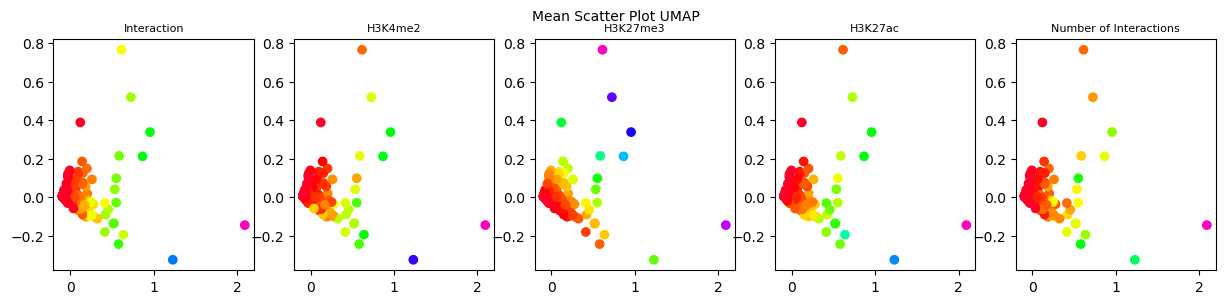

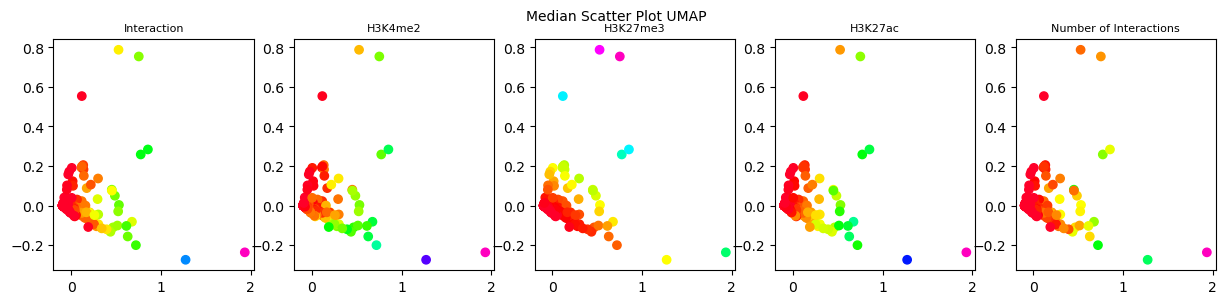

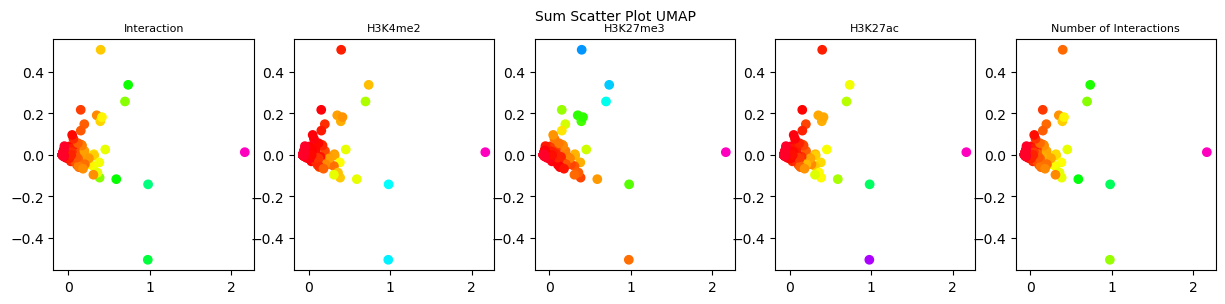

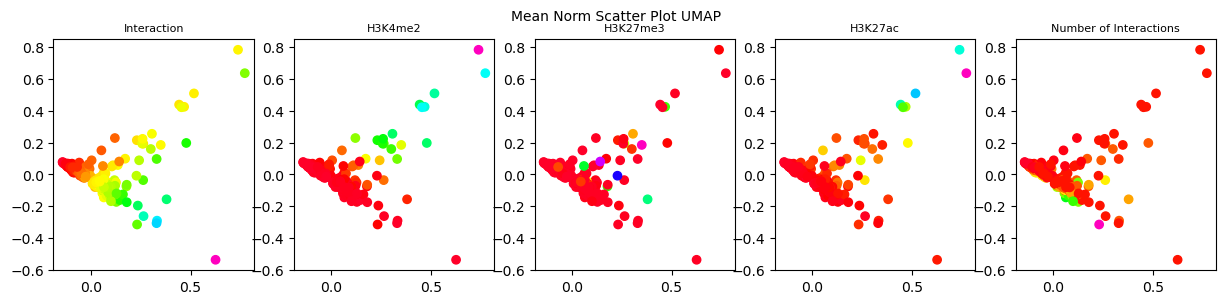

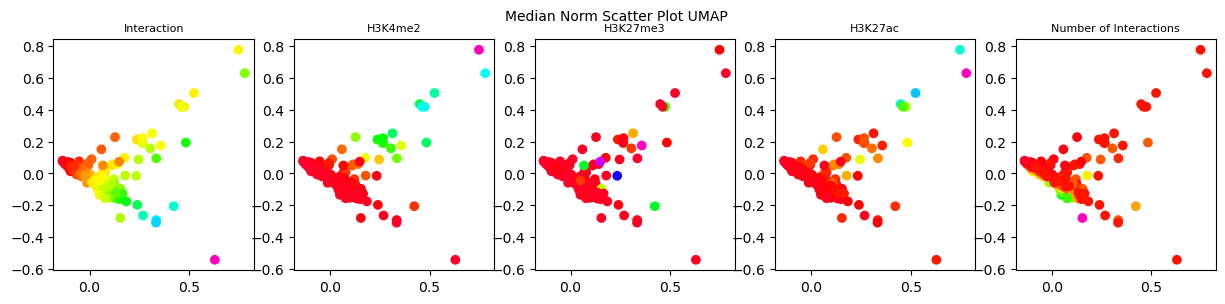

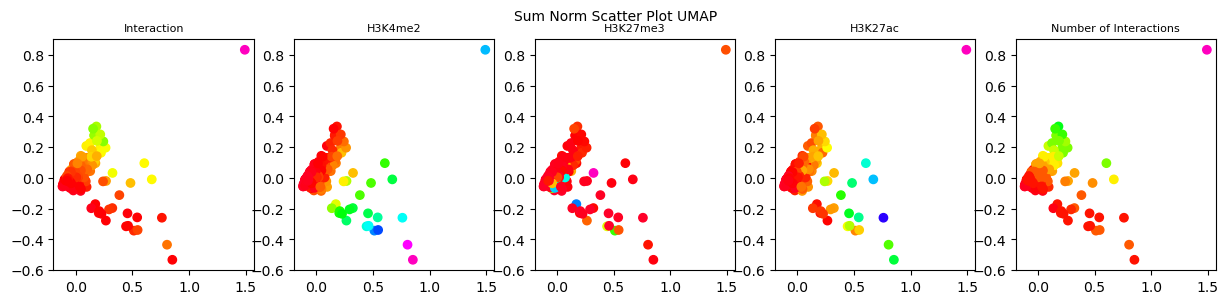

In [202]:
# plt.scatter(pca1_mean, pca2_mean, c=range(len(pca1_mean)), cmap='tab20')
# plt.title("Mean Scatter Plot")
# plt.show()

# plt.scatter(pca1_median, pca2_median, c=range(len(pca1_median)), cmap='tab20')
# plt.title("Median Scatter Plot")
# plt.show()

# plt.scatter(pca1_sum, pca2_sum, c=range(len(pca1_sum)), cmap='tab20')
# plt.title("Sum Scatter Plot")
# plt.show()

# plt.scatter(pca1_mean_norm, pca2_mean_norm, c=range(len(pca1_mean_norm)), cmap='tab20')
# plt.title("Mean Norm Scatter Plot")
# plt.show()

# plt.scatter(pca1_median_norm, pca2_median_norm, c=range(len(pca1_median_norm)), cmap='tab20')
# plt.title("Median Norm Scatter Plot")
# plt.show()

# plt.scatter(pca1_sum_norm, pca2_sum_norm, c=range(len(pca1_sum_norm)), cmap='tab20')
# plt.title("Sum Norm Scatter Plot")
# plt.show()


list_of_titles = ["Interaction", "H3K4me2", "H3K27me3", "H3K27ac", "Number of Interactions"]
list_of_colorings = [community_matrix_mean[:, 0], community_matrix_mean[:, 1], community_matrix_mean[:, 2], community_matrix_mean[:, 3], community_matrix_mean[:, 4]]

plotEmbedding([pca1_mean, pca2_mean], list_of_titles, list_of_colorings, "Mean Scatter Plot UMAP")

list_of_colorings = [community_matrix_median[:, 0], community_matrix_median[:, 1], community_matrix_median[:, 2], community_matrix_median[:, 3], community_matrix_median[:, 4]]
plotEmbedding([pca1_median, pca2_median], list_of_titles, list_of_colorings, "Median Scatter Plot UMAP")

list_of_colorings = [community_matrix_sum[:, 0], community_matrix_sum[:, 1], community_matrix_sum[:, 2], community_matrix_sum[:, 3], community_matrix_sum[:, 4]]
plotEmbedding([pca1_sum, pca2_sum], list_of_titles, list_of_colorings, "Sum Scatter Plot UMAP")

list_of_colorings = [community_matrix_mean_normalized[:, 0], community_matrix_mean_normalized[:, 1], community_matrix_mean_normalized[:, 2], community_matrix_mean_normalized[:, 3], community_matrix_mean_normalized[:, 4]]

plotEmbedding([pca1_mean_norm, pca2_mean_norm], list_of_titles, list_of_colorings, "Mean Norm Scatter Plot UMAP")

list_of_colorings = [community_matrix_median_normalized[:, 0], community_matrix_median_normalized[:, 1], community_matrix_median_normalized[:, 2], community_matrix_median_normalized[:, 3], community_matrix_median_normalized[:, 4]]
plotEmbedding([pca1_median_norm, pca2_median_norm], list_of_titles, list_of_colorings, "Median Norm Scatter Plot UMAP")

list_of_colorings = [community_matrix_sum_normalized[:, 0], community_matrix_sum_normalized[:, 1], community_matrix_sum_normalized[:, 2], community_matrix_sum_normalized[:, 3], community_matrix_sum_normalized[:, 4]]
plotEmbedding([pca1_sum_norm, pca2_sum_norm], list_of_titles, list_of_colorings, "Sum Norm Scatter Plot UMAP")

In [101]:
import umap.umap_ as umap
reducer = umap.UMAP()

In [203]:
embedding_mean = reducer.fit_transform(community_matrix_mean)
embedding_median = reducer.fit_transform(community_matrix_median)
embedding_sum = reducer.fit_transform(community_matrix_sum)
embedding_mean_norm = reducer.fit_transform(community_matrix_mean_normalized)
embedding_median_norm = reducer.fit_transform(community_matrix_median_normalized)
embedding_sum_norm = reducer.fit_transform(community_matrix_sum_normalized)

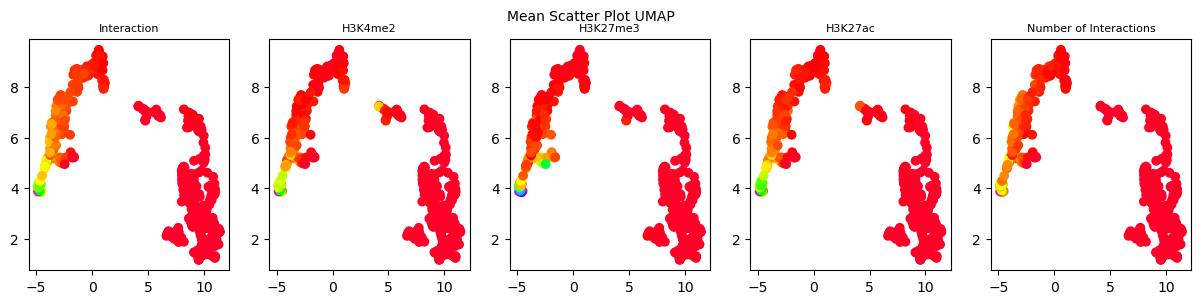

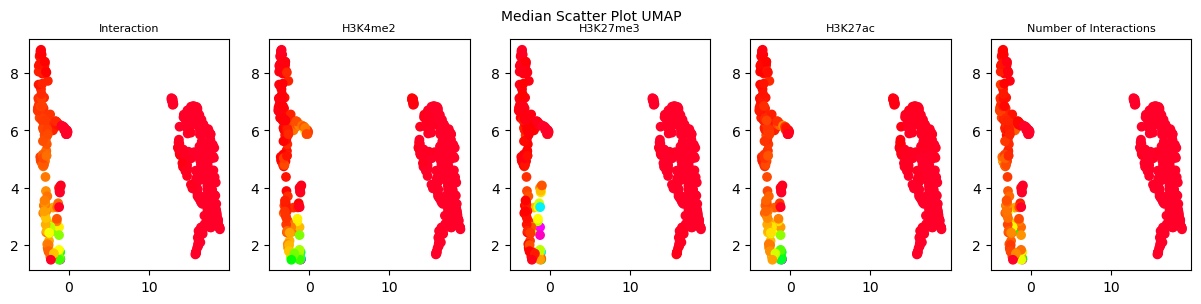

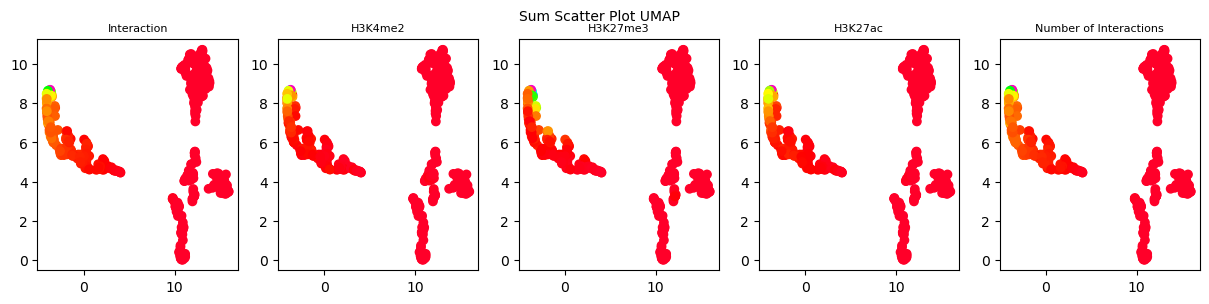

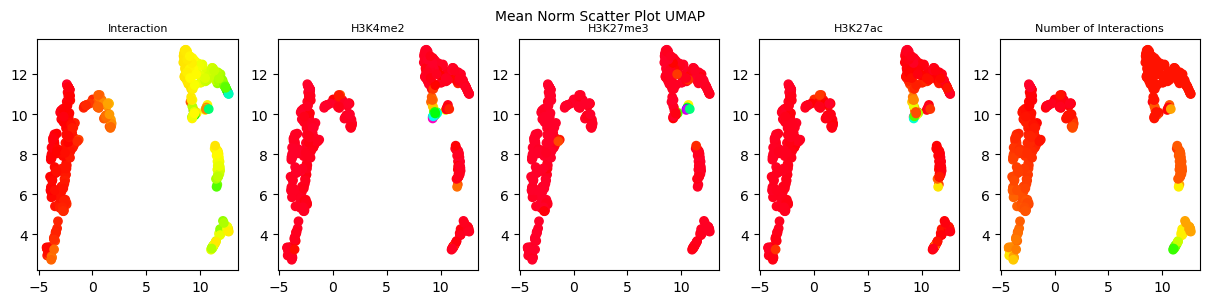

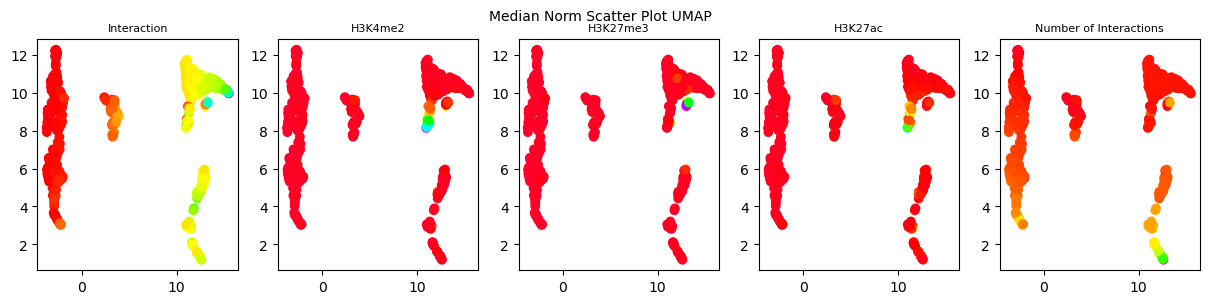

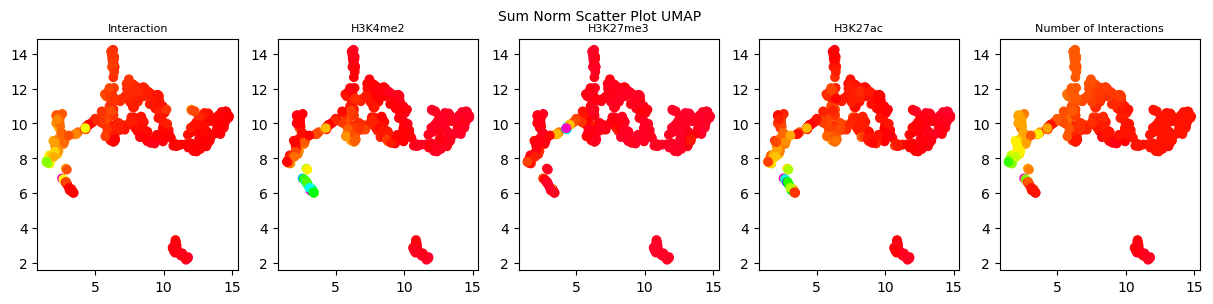

In [204]:
list_of_titles = ["Interaction", "H3K4me2", "H3K27me3", "H3K27ac", "Number of Interactions"]
list_of_colorings = [community_matrix_mean[:, 0], community_matrix_mean[:, 1], community_matrix_mean[:, 2], community_matrix_mean[:, 3], community_matrix_mean[:, 4]]

plotEmbedding([embedding_mean[:, 0], embedding_mean[:, 1]], list_of_titles, list_of_colorings, "Mean Scatter Plot UMAP")

list_of_colorings = [community_matrix_median[:, 0], community_matrix_median[:, 1], community_matrix_median[:, 2], community_matrix_median[:, 3], community_matrix_median[:, 4]]
plotEmbedding([embedding_median[:, 0], embedding_median[:, 1]], list_of_titles, list_of_colorings, "Median Scatter Plot UMAP")

list_of_colorings = [community_matrix_sum[:, 0], community_matrix_sum[:, 1], community_matrix_sum[:, 2], community_matrix_sum[:, 3], community_matrix_sum[:, 4]]
plotEmbedding([embedding_sum[:, 0], embedding_sum[:, 1]], list_of_titles, list_of_colorings, "Sum Scatter Plot UMAP")

list_of_colorings = [community_matrix_mean_normalized[:, 0], community_matrix_mean_normalized[:, 1], community_matrix_mean_normalized[:, 2], community_matrix_mean_normalized[:, 3], community_matrix_mean_normalized[:, 4]]

plotEmbedding([embedding_mean_norm[:, 0], embedding_mean_norm[:, 1]], list_of_titles, list_of_colorings, "Mean Norm Scatter Plot UMAP")

list_of_colorings = [community_matrix_median_normalized[:, 0], community_matrix_median_normalized[:, 1], community_matrix_median_normalized[:, 2], community_matrix_median_normalized[:, 3], community_matrix_median_normalized[:, 4]]
plotEmbedding([embedding_median_norm[:, 0], embedding_median_norm[:, 1]], list_of_titles, list_of_colorings, "Median Norm Scatter Plot UMAP")

list_of_colorings = [community_matrix_sum_normalized[:, 0], community_matrix_sum_normalized[:, 1], community_matrix_sum_normalized[:, 2], community_matrix_sum_normalized[:, 3], community_matrix_sum_normalized[:, 4]]
plotEmbedding([embedding_sum_norm[:, 0], embedding_sum_norm[:, 1]], list_of_titles, list_of_colorings, "Sum Norm Scatter Plot UMAP")



In [193]:
def plotEmbedding(list_of_embeddings, list_of_subtitles, list_of_colorings, title_of_plot, fontsize=8):
    fig, axs = plt.subplots(1, len(list_of_subtitles), figsize=(3 * len(list_of_subtitles), 3))

    for i, (title, coloring) in enumerate(zip(list_of_titles, list_of_colorings)):
        # Plot the first version
        axs[i].scatter(list_of_embeddings[0], list_of_embeddings[1], c=coloring, cmap='gist_rainbow')
        axs[i].set_title(title, fontsize=fontsize)

    fig.suptitle(title_of_plot, fontsize=fontsize+2)
    plt.show()

In [54]:
import matplotlib.pyplot as plt

In [59]:
%matplotlib inline

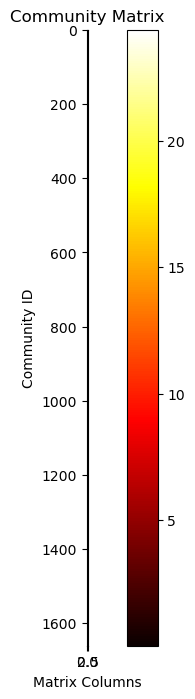

RuntimeError: No mappable was found to use for colorbar creation. First define a mappable such as an image (with imshow) or a contour set (with contourf).

<Figure size 640x480 with 0 Axes>

In [62]:
# plt.heatmap(community_matrix)import matplotlib.pyplot as plt

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.imshow(community_matrix, cmap='hot', interpolation='nearest')
plt.colorbar()
plt.title('Community Matrix')
plt.xlabel('Matrix Columns')
plt.ylabel('Community ID')
plt.show()
plt.colorbar()



In [60]:
plt.show()

In [53]:
elements_per_community

array([ 55., 228., 161., ...,   1.,   1.,   1.])

In [ ]:
np.mean(matrix[community_id, :].tocsr().data)

0.018751868987494782

In [ ]:
matrix[community_id, :].tocsr().data

array([0.00911416, 0.02037817, 0.02676329])

In [ ]:
bw.chroms()

{'chr1': 195471971,
 'chr10': 130694993,
 'chr11': 122082543,
 'chr12': 120129022,
 'chr13': 120421639,
 'chr14': 124902244,
 'chr15': 104043685,
 'chr16': 98207768,
 'chr17': 94987271,
 'chr18': 90702639,
 'chr19': 61431566,
 'chr1_GL456210_random': 169725,
 'chr1_GL456211_random': 241735,
 'chr1_GL456212_random': 153618,
 'chr1_GL456213_random': 39340,
 'chr1_GL456221_random': 206961,
 'chr2': 182113224,
 'chr3': 160039680,
 'chr4': 156508116,
 'chr4_GL456216_random': 66673,
 'chr4_GL456350_random': 227966,
 'chr4_JH584292_random': 14945,
 'chr4_JH584293_random': 207968,
 'chr4_JH584294_random': 191905,
 'chr4_JH584295_random': 1976,
 'chr5': 151834684,
 'chr5_GL456354_random': 195993,
 'chr5_JH584296_random': 199368,
 'chr5_JH584297_random': 205776,
 'chr5_JH584298_random': 184189,
 'chr5_JH584299_random': 953012,
 'chr6': 149736546,
 'chr7': 145441459,
 'chr7_GL456219_random': 175968,
 'chr8': 129401213,
 'chr9': 124595110,
 'chrM': 16299,
 'chrUn_GL456239': 40056,
 'chrUn_GL456359